# IYQPIS: recorded Lenze benchmark review

## tl;dr
The saved benchmark contains 208 detected anomalies out of 320 (65%), 122 false alerts out of 1,576 total records (7.74%), and 112 missed anomalies. This notebook recomputes arithmetic from committed evidence; it does not reload a model or regenerate predictions. Production release remains blocked.

## Context & Methods
Review the published partition using the recorded aggregate counts. The benchmark uses publisher-precomputed features and weak labels. Counts are records, not independent machines or sites. No confidence interval is invented without an appropriate independence model.

### Key Assumptions
The committed acceptance record is the input. Aggregate reconciliation can detect inconsistent totals but cannot independently validate labels, predictions or feature extraction.

Install `requirements-notebooks.txt`, then run `python scripts/execute_notebooks.py`.

In [1]:
from pathlib import Path
import hashlib, json, platform
from importlib.metadata import version
from IPython.display import Markdown, display
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'README.md').is_file(), 'Run from the repository root or notebooks directory'
print('Python:', platform.python_version())
print('Notebook runtime:', {p: version(p) for p in ('nbformat', 'nbclient', 'ipykernel')})
def read_evidence(relative):
    raw = (ROOT / relative).read_bytes()
    print(relative, 'SHA-256:', hashlib.sha256(raw).hexdigest())
    return json.loads(raw)


Python: 3.12.14
Notebook runtime: {'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}


## Data
Read the exact committed acceptance and replay summaries, retaining their hashes. Model/source hashes remain in the acceptance record.

In [2]:
evidence = read_evidence('.azure/lenze-acceptance.json')
consistency = read_evidence('.azure/lenze-decision-consistency.json')
print('Model SHA-256:', evidence['freeze']['model_sha256'])
print('Source SHA-256:', json.dumps(evidence['freeze']['sources'], indent=2))
print('Historical inference job:', evidence['azure_execution'])
print('Historical verification job:', consistency['azure_execution'])

.azure/lenze-acceptance.json SHA-256: ac5c09bfe61c4df989be30abadc5b6718e91fcd8571547a4871199913e57cf7b
.azure/lenze-decision-consistency.json SHA-256: f34c314389dab901f426751e437c0108eaec4ba00ac930a6c7ab0fdf10880105
Model SHA-256: 0d8b42c52499fcabb558bcbef14ab2148050a3645c452aa6cdeb1e436a1e3165
Source SHA-256: {
  "Meta_Data.csv": "684ea6342aaea35c8ff49dc3a8cd98114caece71c181224a10ca3a47b3115634",
  "Original_Features.csv": "1a7523ba6c5c3f06f731b898ef8003d27e01d7bae1e59b19d04fc250770d60e5"
}
Historical inference job: job-iyqpis-dev-data-rptcrd5
Historical verification job: job-iyqpis-dev-data-9ybs2wx


## Results
### 1. Reconcile the complete confusion counts
Missed anomalies and true negatives are derived from the recorded totals. The false-alert metric below divides by **all test rows**, not only healthy rows.

In [3]:
total = evidence['rows']
anomalies = evidence['anomalies']
tp, fp = evidence['true_alerts'], evidence['false_alerts']
fn, tn = anomalies - tp, total - anomalies - fp
assert min(tp, fp, fn, tn) >= 0
assert tp + fp + fn + tn == total
recall, fraction = tp / anomalies, fp / total
assert abs(recall - evidence['recall']) < 1e-12
assert abs(fraction - evidence['false_alert_fraction_of_all_rows']) < 1e-12
assert consistency['rows'] == total and consistency['alerts'] == tp + fp
display(Markdown(f"""| Measure | Recomputed from historical counts |
|---|---|
| Recall | {tp}/{anomalies} = {recall:.2%} |
| False alerts / all records | {fp}/{total} = {fraction:.2%} |
| Missed anomalies | {fn}/{anomalies} |
| Correct normal decisions | {tn}/{total-anomalies} |
| Total alerts | {tp+fp}/{total} |"""))

| Measure | Recomputed from historical counts |
|---|---|
| Recall | 208/320 = 65.00% |
| False alerts / all records | 122/1576 = 7.74% |
| Missed anomalies | 112/320 |
| Correct normal decisions | 1134/1256 |
| Total alerts | 330/1576 |

### 2. See what was missed
All four bars use the same unit: records in the publisher test partition. This view retains the missed anomalies alongside detected ones.

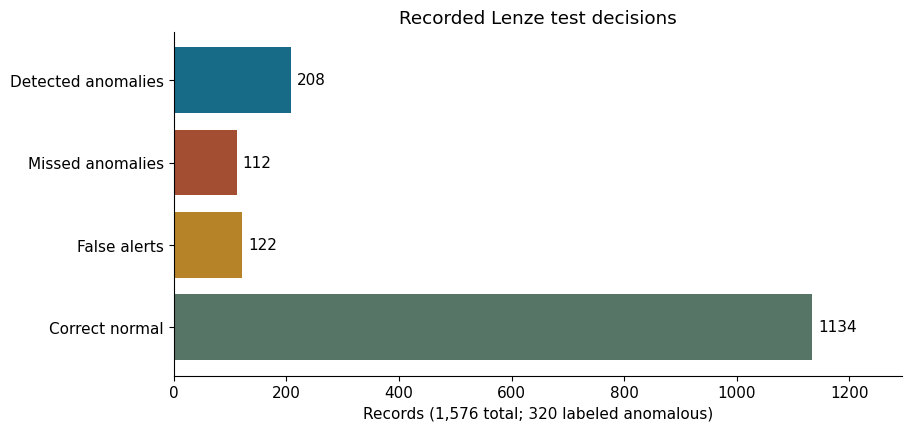

In [4]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 11, 'figure.figsize': (9, 4.2)})
labels = ['Detected anomalies', 'Missed anomalies', 'False alerts', 'Correct normal']
counts = [tp, fn, fp, tn]
fig, ax = plt.subplots(layout='constrained')
bars = ax.barh(labels, counts, color=['#176b87', '#a34d32', '#b78328', '#567566'])
ax.bar_label(bars, padding=4)
ax.set_xlim(0, max(counts)*1.14)
ax.set_xlabel('Records (1,576 total; 320 labeled anomalous)')
ax.set_title('Recorded Lenze test decisions')
ax.invert_yaxis()
ax.spines[['top','right']].set_visible(False)
plt.show()

### 3. Keep replay separate from independent evaluation
The consistency record reports matching binary decisions across three runtimes on the same records. It does not provide a new test population or bitwise score equality.

In [5]:
assert consistency['per_record_decisions_match'] is True
assert consistency['score_bitwise_equality_claimed'] is False
assert evidence['production_release'] == consistency['production_release'] == 'BLOCKED'
print('Recorded runtimes:', ', '.join(consistency['runtimes']))
print('PASS: count/rate reconciliation and blocked release preserved')

Recorded runtimes: Windows Python, Linux Docker, Azure Container Apps Job
PASS: count/rate reconciliation and blocked release preserved


## Takeaways
The historical reference thresholds passed, while 112/320 anomalies were missed. These counts support review of the recorded benchmark only. Full inference replay needs the source CSVs, trusted frozen model, freeze manifest and its independently supplied hash; see [demo prerequisites](../docs/demo.md). Raw-data EDA, baseline/candidate experiments and verified MLflow run links remain open. [Results and measurements](../docs/results.md).